11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Federated Learning Round: 1
Client 1 completed local training
Client 2 completed local training
Client 3 completed local training
Client 4 completed local training
Client 5 completed local training
Global Model Loss: 2.088
Global Model Accuracy: 0.29

Federated Learning Round: 2
Client 1 completed local training
Client 2 completed local training
Client 3 completed local training
Client 4 completed local training
Client 5 completed local training
Global Model Loss: 1.8702
Global Model Accuracy: 0.473

Federated Learning Round: 3
Client 1 completed local training
Client 2 completed local training
Client 3 completed local training
Client 4 completed local training
Client 5 completed local training
Global Model Loss: 1.6728
Global Model Accuracy: 0.616

Federated Learning Round: 4
Client 1 completed local training
Client 2 completed local training
Client 3 completed local training
Client 4 completed local training
Client 5 completed local

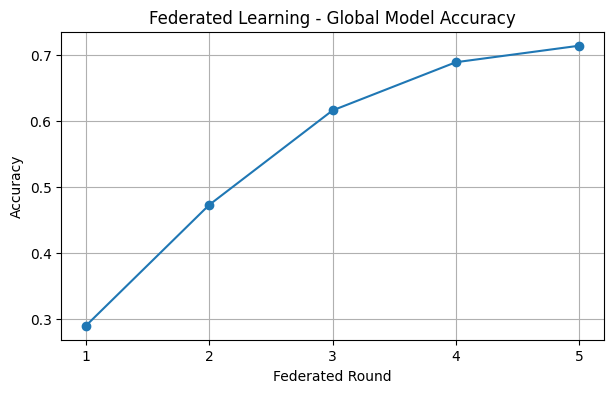

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
x_train = x_train[:5000]
y_train = y_train[:5000]
x_test = x_test[:1000]
y_test = y_test[:1000]

# Split data among 5 simulated clients
num_clients = 5
client_x = np.array_split(x_train, num_clients)
client_y = np.array_split(y_train, num_clients)

# Create model
def create_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")])

    model.compile(
        optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"])
    return model

# Global model
global_model = create_model()

rounds = 5
accuracy_history = []

for round_no in range(rounds):

    print("\nFederated Learning Round:", round_no + 1)

    client_weights = []

    # Train each client locally
    for client in range(num_clients):

        local_model = create_model()
        local_model.set_weights(global_model.get_weights())

        local_model.fit(
            client_x[client],
            client_y[client],
            epochs=1,
            batch_size=32,
            verbose=0)

        client_weights.append(local_model.get_weights())

        print("Client", client + 1, "completed local training")

    # Federated Averaging
    new_weights = []

    for weights in zip(*client_weights):
        new_weights.append(
            np.mean(np.array(weights), axis=0)
        )

    # Update global model
    global_model.set_weights(new_weights)

    # Evaluate global model
    loss, accuracy = global_model.evaluate(
        x_test,
        y_test,
        verbose=0)

    accuracy_history.append(accuracy)

    print("Global Model Loss:", round(loss, 4))
    print("Global Model Accuracy:", round(accuracy, 4))

# Final results
print("\n==============================")
print("FEDERATED LEARNING RESULTS")
print("==============================")
print("Number of Clients:", num_clients)
print("Number of Rounds:", rounds)
print("Final Accuracy:", round(accuracy_history[-1], 4))

# Predictions
predictions = np.argmax(
    global_model.predict(x_test[:10], verbose=0),
    axis=1)

print("\nSample Predictions:")
print("Predicted:", predictions)
print("Actual:   ", y_test[:10])

# Accuracy graph
plt.figure(figsize=(7, 4))

plt.plot(
    range(1, rounds + 1),
    accuracy_history,
    marker="o")

plt.title("Federated Learning - Global Model Accuracy")
plt.xlabel("Federated Round")
plt.ylabel("Accuracy")
plt.xticks(range(1, rounds + 1))
plt.grid(True)
plt.show()